# BiciLogic - L4.3: zones balanced by routed workload

Notebook 05 showed that equal point counts != equal work. Here we balance the **routed workload** directly, using two ideas:

1. a **BHH workload estimate** so we don't have to re-route on every move:
   $$\text{workload(zone)} \approx \underbrace{2\,d(\text{depot}\to\text{zone})}_{\text{access}} + \underbrace{\beta\sqrt{n\,A}}_{\text{internal tour}}$$
2. a **local search** that moves boundary points from the heaviest zone to the lightest until the estimated workloads even out.

We also moved to a **larger study area** (~3 km around central Brussels), since the elongated Ixelles polygon distorts districting.

In [1]:
import sys
sys.path.append("../src")

import osmnx as ox
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
from shapely.geometry import MultiPoint
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans

from geo_utils import distance_matrix
from vrp import solve_vrp

ox.settings.use_cache = True
G = ox.graph_from_point((50.830, 4.370), dist=3000, network_type="bike", simplify=True)
Gp = ox.project_graph(G)
scc = max(nx.strongly_connected_components(Gp), key=len)
Gs = Gp.subgraph(scc).copy()
nodes = list(Gs.nodes)
coords = np.array([[Gs.nodes[n]["x"], Gs.nodes[n]["y"]] for n in nodes])
print(Gs)

MultiDiGraph with 8265 nodes and 18552 edges


## 1. Calibrate beta for our network

BHH is stated for *Euclidean* distance and uniform points; the **form** $\beta\sqrt{nA}$ survives on a road network, but the constant must be **re-calibrated** (it absorbs the detour factor and street structure). We fit $L_{TSP} = \beta\sqrt{nA}$ over random point sets of several sizes.

In [2]:
rng = np.random.default_rng(0)
X, Lv = [], []
for nn in [10, 20, 40, 60]:
    for _ in range(4):
        s = list(rng.choice(nodes, size=nn, replace=False))
        xy = np.array([[Gs.nodes[m]["x"], Gs.nodes[m]["y"]] for m in s])
        A = MultiPoint(xy).convex_hull.area
        _, L = solve_vrp(distance_matrix(Gs, s), 1, objective="sum", time_limit_s=2)
        X.append(np.sqrt(nn * A)); Lv.append(L[0])
X, Lv = np.array(X), np.array(Lv)
BETA = float((X @ Lv) / (X @ X))
R2 = 1 - ((Lv - BETA * X) ** 2).sum() / ((Lv - Lv.mean()) ** 2).sum()
print(f"beta_net = {BETA:.3f}   R^2 = {R2:.3f}   (Euclidean-uniform reference ~0.7124)")

beta_net = 1.347   R^2 = 0.912   (Euclidean-uniform reference ~0.7124)


## 2. Demand, depot, and three partitions

- **k-means** (Euclidean), **count-balanced** (network distance, tiled Hungarian), and **BHH-rebalanced** (this notebook).

In [3]:
rng = np.random.default_rng(3)
hot = coords[rng.choice(len(nodes), size=4, replace=False)]
d_near = np.sqrt(((coords[:, None, :] - hot[None, :, :]) ** 2).sum(-1)).min(axis=1)
w = np.exp(-d_near / 500.0) + 0.15; w /= w.sum()
didx = rng.choice(len(nodes), size=200, replace=False, p=w)
demand_nodes = [nodes[i] for i in didx]
demand_xy = coords[didx]
n, k = len(demand_nodes), 4
depot = ox.nearest_nodes(Gs, X=demand_xy[:, 0].mean(), Y=demand_xy[:, 1].mean())
ddepot = nx.single_source_dijkstra_path_length(Gs, depot, weight="length")

km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(demand_xy)
labels_km = km.labels_

seeds = ox.nearest_nodes(Gs, X=km.cluster_centers_[:, 0], Y=km.cluster_centers_[:, 1])
netdist = np.zeros((n, k))
for z, s in enumerate(seeds):
    dd = nx.single_source_dijkstra_path_length(Gs, s, weight="length")
    netdist[:, z] = [dd.get(nd, 1e9) for nd in demand_nodes]
cap = int(np.ceil(n / k))
row, col = linear_sum_assignment(np.repeat(netdist, cap, axis=1))
labels_bal = np.empty(n, dtype=int); labels_bal[row] = col // cap

## 3. Rebalance by estimated routed workload

Greedy local search: estimate each zone's workload with BHH, move the most *borderline* point from the heaviest zone to the lightest, repeat. (Caveat: this version does not yet enforce **contiguity** - balance and compactness compete, so zones can intermix at the edges. Enforcing connectivity in the swap is the next refinement.)

In [4]:
def hull_area(xy):
    return MultiPoint(xy).convex_hull.area if len(xy) >= 3 else 0.0

def bhh_w(idx, center):
    return 2 * ddepot.get(center, 0) + BETA * np.sqrt(len(idx) * hull_area(demand_xy[idx]))

labels = labels_bal.copy()
best_labels, best_ratio = labels.copy(), np.inf
for _ in range(80):
    zones = [np.where(labels == z)[0] for z in range(k)]
    centers = [ox.nearest_nodes(Gs, X=demand_xy[zi, 0].mean(), Y=demand_xy[zi, 1].mean()) for zi in zones]
    wl = np.array([bhh_w(zones[z], centers[z]) for z in range(k)])
    ratio = wl.max() / wl.min()
    if ratio < best_ratio:
        best_ratio, best_labels = ratio, labels.copy()
    if ratio < 1.05:
        break
    zmax, zmin = int(wl.argmax()), int(wl.argmin())
    dmin = nx.single_source_dijkstra_path_length(Gs, centers[zmin], weight="length")
    dmax = nx.single_source_dijkstra_path_length(Gs, centers[zmax], weight="length")
    cand = zones[zmax]
    score = [dmin.get(demand_nodes[i], 1e9) - dmax.get(demand_nodes[i], 1e9) for i in cand]
    labels[cand[int(np.argmin(score))]] = zmin
labels_bhh = best_labels

## 4. Validate: actual routed workload (route each zone for real)

In [5]:
def routed_loads(lab):
    out = []
    for z in range(k):
        zn = [demand_nodes[i] for i in range(n) if lab[i] == z]
        _, L = solve_vrp(distance_matrix(Gs, [depot] + zn), 1, objective="sum", time_limit_s=2)
        out.append(L[0])
    return np.array(out)

for name, lab in [("k-means (Euclid)", labels_km),
                  ("count-balanced", labels_bal),
                  ("BHH-rebalanced", labels_bhh)]:
    c = np.bincount(lab, minlength=k); L = routed_loads(lab)
    print(f"{name:18s} counts {c.tolist()} (imb {c.max()/c.min():.2f}) | "
          f"routed km {(L/1000).round(1).tolist()} (imb {L.max()/L.min():.2f})")

k-means (Euclid)   counts [47, 40, 84, 29] (imb 2.90) | routed km [23.7, 25.8, 28.5, 23.3] (imb 1.22)


count-balanced     counts [50, 50, 50, 50] (imb 1.00) | routed km [25.5, 31.3, 16.8, 30.4] (imb 1.86)


BHH-rebalanced     counts [56, 43, 60, 41] (imb 1.46) | routed km [28.7, 28.3, 25.8, 27.5] (imb 1.11)


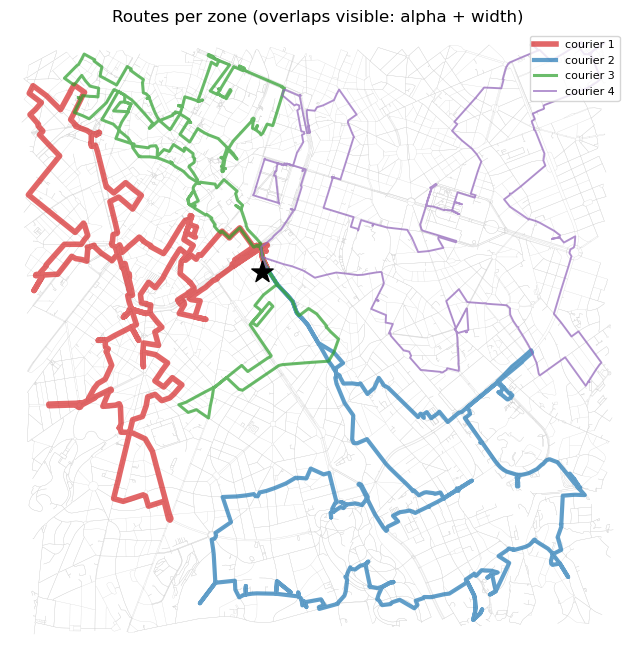

In [6]:
def full_path(seq):
    p = []
    for a, b in zip(seq[:-1], seq[1:]):
        q = nx.shortest_path(Gs, a, b, weight="length"); p += q[1:] if p else q
    return p

colors = ["tab:red", "tab:blue", "tab:green", "tab:purple"]
fig, ax = ox.plot_graph(Gs, node_size=0, edge_linewidth=0.2, edge_color="lightgray",
                        bgcolor="white", show=False, close=False)
lws = [4.0, 3.0, 2.2, 1.4]   # decreasing width + alpha so overlapping routes stay visible
for z in range(k):
    zn = [demand_nodes[i] for i in range(n) if labels_bhh[i] == z]
    r, _ = solve_vrp(distance_matrix(Gs, [depot] + zn), 1, objective="sum", time_limit_s=2)
    fp = full_path([([depot] + zn)[i] for i in r[0]])
    ax.plot([Gs.nodes[m]["x"] for m in fp], [Gs.nodes[m]["y"] for m in fp],
            color=colors[z], lw=lws[z], alpha=0.7, zorder=4, label=f"courier {z+1}")
ax.scatter(Gs.nodes[depot]["x"], Gs.nodes[depot]["y"], marker="*", s=260, c="black", zorder=6)
ax.legend(loc="upper right", fontsize=8)
ax.set_title("Routes per zone (overlaps visible: alpha + width)")
plt.show()

## Takeaways

- Balancing the **routed workload** (via the BHH estimate) gives near-equal real km per courier (imbalance 1.11), where equal-count zones did not (1.86).
- The estimate let us rebalance **without re-routing** every move; we routed only at the end to validate.
- **Open issue:** contiguity/compactness was traded for balance. Next: enforce connected zones in the swap.

**Next (L4.4, the hero):** make the zones **robust** - simulate many demand days and measure how stable the balance stays, optimizing expected workload with low variance.